# Local Matching for OurAirports

Finds duplicate records **within** the normalized OurAirports dataset (`ourairportsNormalized.csv`): the same real-world airport, heliport, ... stored as more than one row.

The pipeline follows the Kaggle and Wikidata local matching notebooks. Candidate pairs are generated by two complementary blocking rules, and the union of their candidates is scored:

- **Rule A: `countryCode` + distinguishing `name` token.** Two records are candidates if they are in the same country and share a `name` token that is not a common word.
- **Rule B: geographic grid (H3).** Two records are candidates if they lie in the same or in adjacent H3 cells, regardless of name or country.
- **Rule C (ICAO / IATA code) is not used**: both codes are unique in OurAirports, so the rule would produce no candidates (checked below).

**Steps**

1. Load the normalized dataset
2. Blocking Rule A: `countryCode` + distinguishing `name` tokens
3. Blocking Rule B: geographic grid (H3)
4. Rule C check: ICAO / IATA uniqueness
5. Combine and filter candidates: union of both rules, no self-pairs, no reversed duplicates
6. Coverage check: records reached by neither rule
7. Per-attribute comparators (name, geo distance, designator, type, isoRegion, city)
8. Score candidates with `RuleBasedMatcher`
9. Score distribution
10. Sanity check against the duplicates OurAirports labels itself
11. Manual review of high-scoring candidates
12. Save the matches

**OurAirports-specific notes** (they explain why some settings differ from Kaggle / Wikidata):
- **Much larger dataset** (86 151 records vs 6 391 / 24 859) → `COMMON_TOKEN_THRESHOLD = 30`.
- **Every record has coordinates** → Rule B reaches every record, and the geo comparator never needs a neutral value.
- **Dense heliport clusters**: ~23 000 heliports, many on neighbouring buildings 50–200 m apart (`north tower` / `south tower` helipads). Duplicates of a heliport have (almost) identical coordinates, so the geo comparator uses `max_distance_km = 0.1` for heliports and `1.0` for everything else (an airfield is often more than 1 km long, so two records of it can lie a few hundred metres apart), instead of 2 km for all records.
- **Designators distinguish facilities**: `block 997` vs `block 998`, `plaza i` vs `plaza ii`, `tower b`, `n1` / `n2`, `north` / `south` → extra `DesignatorComparator`.
- **OurAirports labels some duplicates itself** (`duplicate mukho port heliport`): the label is removed before name comparison, and the labelled records are used as a small gold standard.
- **Not decided yet:** whether a `closed` record and an active record at the same site (an old pad and its replacement) count as duplicates. Such pairs are flagged in the output (`closed_vs_active`) so the team can decide.

In [1]:
from collections import Counter
from pathlib import Path
import math
import re

import h3
import matplotlib.pyplot as plt
import pandas as pd

from PyDI.entitymatching import TokenBlocker, RuleBasedMatcher
from PyDI.entitymatching import StringComparator
from PyDI.entitymatching.base import BaseComparator

## Load the normalized dataset

`keep_default_na=False` is required: Namibia's `countryCode` is the text `NA`, which pandas would otherwise read as missing (see the normalization notebook).

In [2]:
DATA_DIR = Path("../../data/normalized_outputs")
INPUT_CSV = DATA_DIR / "ourairportsNormalized.csv"

df = pd.read_csv(INPUT_CSV, keep_default_na=False, na_values=[""], low_memory=False)
df.attrs["source"] = "ourairports"

print(f"Loaded {len(df)} records")
print(f"Columns: {list(df.columns)}")
print(f"\nMissing values: {df[['name', 'countryCode', 'lat', 'lon', 'city', 'icao', 'iata']].isna().sum().to_dict()}")
print(f"\nRecord types: {df['type'].value_counts().to_dict()}")
df.head(5)

Loaded 86151 records
Columns: ['id', 'name', 'type', 'scheduledService', 'localCode', 'lat', 'lon', 'elevation', 'countryCode', 'isoRegion', 'city', 'runway_lengthFt', 'runway_widthFt', 'runway_surface', 'runway_lighted', 'runway_closed', 'runway_leIdent', 'runway_heIdent', 'wikipedia', 'continent', 'iata', 'icao', 'countryName']

Missing values: {'name': 1, 'countryCode': 0, 'lat': 0, 'lon': 0, 'city': 4748, 'icao': 75621, 'iata': 77097}

Record types: {'small_airport': 42762, 'heliport': 23224, 'closed': 13548, 'medium_airport': 4106, 'seaplane_base': 1273, 'large_airport': 1175, 'balloonport': 63}


,id,name,type,scheduledService,localCode,lat,lon,elevation,countryCode,isoRegion,...,runway_surface,runway_lighted,runway_closed,runway_leIdent,runway_heIdent,wikipedia,continent,iata,icao,countryName
0,oa_1,total rf heliport,heliport,False,00A,40.070985,-74.933689,3.3528,US,US-PA,...,ASPH-G,false,false,H1,NaN,NaN,NaN,NaN,NaN,united states
1,oa_2,aero b ranch airport,small_airport,False,00AA,38.704022,-101.473911,1046.9880,US,US-KS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,united states
2,oa_3,lowell field,small_airport,False,00AK,59.947733,-151.692524,137.1600,US,US-AK,...,GRVL,false,false,N,S,NaN,NaN,NaN,NaN,united states
3,oa_4,epps airpark,small_airport,False,00AL,34.864799,-86.770302,249.9360,US,US-AL,...,TURF,false,false,01,19,NaN,NaN,NaN,NaN,united states
4,oa_5,katmai lodge airport,small_airport,False,00AN,59.093287,-156.456699,24.3840,US,US-AK,...,GVL,false,false,3,21,NaN,NaN,NaN,NaN,united states


## Blocking Rule A: `countryCode` + distinguishing `name` tokens

- Goal: generate candidate duplicate pairs by self-blocking. Generic words in `name` (`airport`, `heliport`, `fazenda`, `building`, ...) must not be used as blocking keys because they would create huge blocks with thousands of unrelated records.

- Method: `TokenBlocker` on `name`, same as Kaggle / Wikidata.
  - Tokens that appear in more than `COMMON_TOKEN_THRESHOLD` distinct names are treated as non-distinguishing and excluded; this list is derived from the data (document frequency).
  - `countryCode` is prepended to each remaining token (e.g. `"US::bensalem"`), so a pair is a candidate only if the two records share a distinguishing token **and** have the same country.

- `COMMON_TOKEN_THRESHOLD = 30`: OurAirports is ~3.5x larger than Wikidata, so the same document frequency is less "common" here. The table below shows the trade-off. A lower threshold leaves more records without any token, a higher one creates more candidate pairs. Records without a token are still reached by Rule B, because every record has coordinates.

In [3]:
token_doc_freq = Counter()
for name in df["name"].dropna():
    token_doc_freq.update(set(t for t in name.split() if len(t) >= 2))

# Trade-off table for the threshold choice
rows = []
for threshold in [10, 20, 30, 50, 100]:
    common = {t for t, c in token_doc_freq.items() if c > threshold}
    no_token = df["name"].apply(
        lambda n: not isinstance(n, str) or not [t for t in n.split() if len(t) >= 2 and t not in common]
    )
    rows.append({"threshold": threshold, "excluded_tokens": len(common), "records_without_token": int(no_token.sum()),
                 "share_without_token": f"{no_token.mean():.1%}"})
display(pd.DataFrame(rows))

,threshold,excluded_tokens,records_without_token,share_without_token
0,10,1696,15115,17.5%
1,20,814,8837,10.3%
2,30,526,6173,7.2%
3,50,299,3439,4.0%
4,100,147,1602,1.9%


### Generate blocking key column

In [4]:
COMMON_TOKEN_THRESHOLD = 30

COMMON_TOKENS = {t for t, c in token_doc_freq.items() if c > COMMON_TOKEN_THRESHOLD}
print(f"Excluding {len(COMMON_TOKENS)} tokens that each appear in more than {COMMON_TOKEN_THRESHOLD} names")
print(f"Most frequent excluded tokens: {[t for t, _ in token_doc_freq.most_common(20)]}")

def blocking_tokenizer(text):
    if not isinstance(text, str):
        return []
    return [t for t in text.split() if len(t) >= 2 and t not in COMMON_TOKENS]

print("\nExample tokens kept for blocking:")
for name in df["name"].dropna().head(5):
    print(f"  {name!r:45s} -> {blocking_tokenizer(name)}")

no_tokens_left = df["name"].apply(lambda n: len(blocking_tokenizer(n)) == 0)
print(f"\n{no_tokens_left.sum()} records ({no_tokens_left.mean():.1%}) have no distinguishing token left "
      "and cannot be reached by Rule A. They are still reached by Rule B.")

Excluding 526 tokens that each appear in more than 30 names
Most frequent excluded tokens: ['airport', 'heliport', 'airfield', 'airstrip', 'helipad', 'hospital', 'fazenda', 'field', 'base', 'ranch', 'air', 'center', 'municipal', 'international', 'medical', 'seaplane', 'landing', 'county', 'lake', 'farm']

Example tokens kept for blocking:
  'total rf heliport'                           -> ['total', 'rf']
  'aero b ranch airport'                        -> []
  'lowell field'                                -> ['lowell']
  'epps airpark'                                -> ['epps']
  'katmai lodge airport'                        -> ['katmai']

6173 records (7.2%) have no distinguishing token left and cannot be reached by Rule A. They are still reached by Rule B.


### Implement Blocking to generate candidate pairs

In [5]:
def make_blocking_text(row):
    if pd.isna(row["countryCode"]) or pd.isna(row["name"]):
        return None
    return f"{row['countryCode']}||{row['name']}"

df["name_with_country"] = df.apply(make_blocking_text, axis=1)

def country_scoped_tokenizer(text):
    if not isinstance(text, str):
        return []
    country, _, name = text.partition("||")
    return [f"{country}::{t}" for t in blocking_tokenizer(name)]

blocker_token = TokenBlocker(
    df_left=df,
    df_right=df,
    column="name_with_country",
    id_column="id",
    tokenizer=country_scoped_tokenizer,
)

candidates_token = blocker_token.materialize()
print(f"Raw candidate pairs from token blocking: {len(candidates_token)}")

Raw candidate pairs from token blocking: 377714


### Deduplication of pairs
- Goal: remove the noise self-blocking produces.
- Method: drop `id1 == id2`, and keep one canonical direction per pair (`id1 < id2`) to drop `(A,B)`/`(B,A)` duplicates.

In [6]:
def canonical_pairs(pairs):
    pairs = pairs[pairs["id1"] != pairs["id2"]].copy()
    swap = pairs["id1"] > pairs["id2"]
    pairs.loc[swap, ["id1", "id2"]] = pairs.loc[swap, ["id2", "id1"]].values
    return pairs.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

candidates_token = canonical_pairs(candidates_token)
print(f"Candidate pairs after filtering: {len(candidates_token)}")
candidates_token.head(5)

Candidate pairs after filtering: 148868


,id1,id2,block_key
0,oa_2373,oa_3,US::sanford
1,oa_3,oa_4219,US::sanford
2,oa_3,oa_4324,US::sanford
3,oa_3,oa_9186,US::sanford
4,oa_16693,oa_3,US::sanford


## Blocking Rule B: Geographic grid (H3)

- Goal: find duplicate pairs that Rule A cannot reach: records whose names are generic or share no distinguishing token.

- Method: same as Kaggle / Wikidata. Map each record to an [H3](https://h3geo.org/) hexagonal cell at resolution `RESOLUTION = 9` (average edge length ≈ 174 m) and use `TokenBlocker` on the H3 cell IDs.
  - Each record emits **7 tokens**: the cell containing it plus its 6 neighbouring cells (`h3.grid_disk(cell, 1)`). Two records in the same or adjacent cells always share a token.
  - `countryCode` is deliberately **not** part of the token.
  - OurAirports has coordinates for every record and no `(0, 0)` sentinel, so every record emits tokens.

- Implementation: `TokenBlocker`'s tokenizer only sees one column's text; the H3 tokens are precomputed per record and looked up by `id`.

### Define H3 grid token generation function

In [7]:
RESOLUTION = 9

def geo_h3_tokens(row):
    lat, lon = row["lat"], row["lon"]
    if pd.isna(lat) or pd.isna(lon):
        return []
    center = h3.latlng_to_cell(lat, lon, RESOLUTION)
    return list(h3.grid_disk(center, 1))

print("Test: Frankfurt am Main Airport (50.0333, 8.5706)")
print(geo_h3_tokens({"lat": 50.0333, "lon": 8.5706}))

Test: Frankfurt am Main Airport (50.0333, 8.5706)
['891faea826bffff', '891faea91b7ffff', '891faea91a7ffff', '891faea9cd3ffff', '891faea826fffff', '891faea8263ffff', '891faea827bffff']


### Generate `geo_grid_tokens` column

In [8]:
df["geo_grid_tokens"] = df.apply(geo_h3_tokens, axis=1)
grid_token_lookup = df.set_index("id")["geo_grid_tokens"].to_dict()

no_coords = df["geo_grid_tokens"].apply(len) == 0
print(f"{no_coords.sum()} records have no coordinates → not reachable by Rule B")

0 records have no coordinates → not reachable by Rule B


### Implement Blocking to generate candidate pairs

In [9]:
def grid_tokenizer(record_id):
    return grid_token_lookup.get(record_id, [])

df["id_as_text"] = df["id"]

blocker_geo = TokenBlocker(
    df_left=df,
    df_right=df,
    column="id_as_text",
    id_column="id",
    tokenizer=grid_tokenizer,
)

candidates_geo = blocker_geo.materialize()
print(f"Raw candidate pairs from geo blocking: {len(candidates_geo)}")

candidates_geo = canonical_pairs(candidates_geo)
print(f"Candidate pairs after filtering: {len(candidates_geo)}")

Raw candidate pairs from geo blocking: 142785
Candidate pairs after filtering: 28317


## Rule C check: ICAO / IATA codes are unique

The Kaggle notebook adds a third rule that pairs records sharing an ICAO or IATA code. In OurAirports both codes are unique by construction (every value occurs once), so this rule would produce no candidate pairs and is not used.

In [10]:
for col in ["icao", "iata"]:
    values = df[col].dropna()
    print(f"{col}: {len(values)} non-null values, {values.duplicated().sum()} duplicated")

icao: 10530 non-null values, 0 duplicated
iata: 9054 non-null values, 0 duplicated


## Concatenate candidate pairs from both blocking rules

In [11]:
candidates = canonical_pairs(pd.concat([candidates_token, candidates_geo], axis=0))
print(f"All candidate pairs after deduplication: {len(candidates)}")

def pair_set(df_pairs):
    return set(zip(df_pairs["id1"], df_pairs["id2"]))

s_token, s_geo = pair_set(candidates_token), pair_set(candidates_geo)
print(f"Rule A: {len(s_token)} | Rule B: {len(s_geo)} | both: {len(s_token & s_geo)} | union: {len(s_token | s_geo)}")
print(f"Only A: {len(s_token - s_geo)} | Only B: {len(s_geo - s_token)}")

All candidate pairs after deduplication: 173352


Rule A: 148868 | Rule B: 28317 | both: 3833 | union: 173352


Only A: 145035 | Only B: 24484


## Coverage check: records reached by neither blocking rule

A record is unreachable if Rule A cannot reach it (no `countryCode`, or no distinguishing `name` token left) **and** Rule B cannot reach it (no coordinates). Because every OurAirports record has coordinates, this should be empty.

In [12]:
not_by_rule_a = no_tokens_left | df["countryCode"].isna()
not_by_rule_b = df["geo_grid_tokens"].apply(len) == 0

uncovered = not_by_rule_a & not_by_rule_b
print(f"{uncovered.sum()} records unreachable by any rule")
df.loc[uncovered, ["id", "name", "countryCode", "lat", "lon"]]

0 records unreachable by any rule


,id,name,countryCode,lat,lon


## Per-attribute comparators

Goal: a similarity score per attribute for each candidate pair.

| Attribute | Comparator | Rationale |
|---|---|---|
| `name_core` | Jaro-Winkler | `name` without OurAirports' own `duplicate` label (`duplicate fort lee heliport` → `fort lee heliport`) |
| `lat`/`lon` | Haversine, `max_distance_km` = 0.1 for heliports, 1.0 otherwise | Different heliports on neighbouring buildings lie 50–200 m apart and would all score high with the 2 km used for Kaggle / Wikidata, while labelled heliport duplicates lie < 10 m apart. Airfields are much larger: the labelled duplicate `duplicateeast kirkby airfield` lies 229 m from `east kirkby airfield`. A pair counts as a heliport pair if either record has type `heliport` or a name containing `heli…` (closed heliports have type `closed`) |
| `name_core` | `DesignatorComparator` | Numbers, roman numerals, single letters and compass words mark *different* facilities at the same site: `block 997` / `block 998`, `plaza i` / `plaza ii`, `tower b`, `n1` / `n2`, `north` / `south`. 1.0 if both names carry the same designators, 0.0 if they carry different ones, 0.5 if only one side has any |
| `type` | `TypeComparator` | 1.0 for the same type; 0.5 if one side is `closed` (its original type is unknown) or both are airports of different size; 0.0 otherwise (e.g. a heliport and an airport at the same site are different facilities) |
| `isoRegion` | Exact | Cheap extra check; separates same-named records in different regions |
| `city` | Jaro-Winkler, neutral on missing | `city` is missing for ~5 % of records; the built-in `StringComparator` would return 0.0 there |

`icao` / `iata` are not used: they are unique in OurAirports, so two records never share a code.

In [13]:
# OurAirports marks some duplicate records itself ("duplicate fort lee heliport").
# The label is sometimes fused to the next word ("duplicateyeg"), so match it as a prefix of a word.
DUPLICATE_LABEL = re.compile(r"\bduplicate")

def name_core(name):
    if not isinstance(name, str):
        return name
    core = " ".join(DUPLICATE_LABEL.sub(" ", name).split())
    return core or pd.NA

df["name_core"] = df["name"].apply(name_core)
df["is_labelled_duplicate"] = df["name"].str.contains(DUPLICATE_LABEL, na=False)
print(f"{df['is_labelled_duplicate'].sum()} records carry OurAirports' own 'duplicate' label, e.g.:")
df.loc[df["is_labelled_duplicate"], ["id", "name", "name_core", "type"]].head(5)

131 records carry OurAirports' own 'duplicate' label, e.g.:


,id,name,name_core,type
2559,oa_2560,duplicate fort lee heliport,fort lee heliport,heliport
10991,oa_10992,duplicate aeropuerto pergamino,aeropuerto pergamino,medium_airport
11231,oa_11232,duplicate utai airstrip,utai airstrip,small_airport
12766,oa_12767,duplicate erquelinnes dz,erquelinnes dz,heliport
12952,oa_12953,duplicate sapareva banay airport,sapareva banay airport,small_airport


In [14]:
name_comp = StringComparator(column="name_core", similarity_function="jaro_winkler")


HELI_NAME = re.compile(r"\bheli")


def is_heliport(record):
    # Closed heliports have type 'closed', so the name is checked as well
    return record.get("type") == "heliport" or bool(HELI_NAME.search(str(record.get("name_core", ""))))


class GeoDistanceComparator(BaseComparator):
    # Haversine great-circle distance -> similarity score, with a tighter distance limit for heliports

    def __init__(self, lat_column="lat", lon_column="lon", heliport_max_km=0.1, default_max_km=1.0):
        super().__init__(name="geo_distance")
        self.lat_column = lat_column
        self.lon_column = lon_column
        self.heliport_max_km = heliport_max_km
        self.default_max_km = default_max_km

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
            return 0.5  # neutral; does not occur in OurAirports
        distance_km = self.haversine_km(lat1, lon1, lat2, lon2)
        if is_heliport(record1) or is_heliport(record2):
            max_km = self.heliport_max_km
        else:
            max_km = self.default_max_km
        return max(0.0, 1.0 - distance_km / max_km)

    @staticmethod
    def haversine_km(lat1, lon1, lat2, lon2):
        R = 6371.0
        phi1, phi2 = math.radians(lat1), math.radians(lat2)
        dphi = math.radians(lat2 - lat1)
        dlambda = math.radians(lon2 - lon1)
        a = (math.sin(dphi / 2) ** 2
             + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2)
        return 2 * R * math.asin(math.sqrt(a))


geo_comp = GeoDistanceComparator(heliport_max_km=0.1, default_max_km=1.0)


ROMAN_NUMERALS = {"i", "ii", "iii", "iv", "v", "vi", "vii", "viii", "ix", "x", "xi", "xii"}
POSITION_WORDS = {"north", "south", "east", "west", "northeast", "northwest", "southeast", "southwest",
                  "upper", "lower", "old", "new"}
DIGITS = re.compile(r"\d+")


def designators(name):
    # Tokens that tell facilities at the same site apart: numbers, roman numerals, single letters, positions
    found = set()
    if not isinstance(name, str):
        return found
    for token in name.split():
        found.update(DIGITS.findall(token))
        if token in ROMAN_NUMERALS or token in POSITION_WORDS or (len(token) == 1 and token.isalpha()):
            found.add(token)
    return found


class DesignatorComparator(BaseComparator):
    # 1.0 same designators, 0.0 conflicting designators, 0.5 only one side has any

    def __init__(self, column="name_core"):
        super().__init__(name="designator")
        self.column = column

    def compare(self, record1, record2):
        d1, d2 = designators(record1.get(self.column)), designators(record2.get(self.column))
        if d1 == d2:
            return 1.0
        if not d1 or not d2:
            return 0.5
        return 0.0


designator_comp = DesignatorComparator()


AIRPORT_TYPES = {"small_airport", "medium_airport", "large_airport"}


class TypeComparator(BaseComparator):
    # 1.0 same type, 0.5 closed or airports of different size, 0.0 different kinds of facility

    def __init__(self, column="type"):
        super().__init__(name="type")
        self.column = column

    def compare(self, record1, record2):
        t1, t2 = record1.get(self.column), record2.get(self.column)
        if t1 == t2:
            return 1.0
        if "closed" in (t1, t2) or (t1 in AIRPORT_TYPES and t2 in AIRPORT_TYPES):
            return 0.5
        return 0.0


type_comp = TypeComparator()


class ExactComparator(BaseComparator):
    # Exact match; neutral (0.5) when either side is missing

    def __init__(self, column):
        super().__init__(name=f"{column}_exact")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if pd.isna(v1) or pd.isna(v2):
            return 0.5
        return 1.0 if v1 == v2 else 0.0


iso_region_comp = ExactComparator("isoRegion")


class NeutralOnMissing(BaseComparator):
    # Wraps a comparator so that a missing value on either side gives 0.5 instead of 0.0

    def __init__(self, comparator, column):
        super().__init__(name=comparator.name)
        self.comparator = comparator
        self.column = column

    def compare(self, record1, record2):
        if pd.isna(record1.get(self.column)) or pd.isna(record2.get(self.column)):
            return 0.5
        return self.comparator.compare(record1, record2)


city_comp = NeutralOnMissing(StringComparator(column="city", similarity_function="jaro_winkler"), "city")

comparators = [name_comp, geo_comp, designator_comp, type_comp, iso_region_comp, city_comp]
comparator_names = ["name", "geo_distance", "designator", "type", "isoRegion", "city"]

# Sanity check on two known cases
idx = df.set_index("id")
examples = {
    "labelled heliport duplicate": ("oa_2560", "oa_54373"),   # duplicate fort lee heliport / fort lee heliport
    "labelled airfield duplicate": ("oa_30132", "oa_28979"),  # 229 m apart
    "neighbouring towers": ("oa_73690", "oa_73691"),          # watt plaza north / south tower helipad
}
for label, (a, b) in examples.items():
    r1, r2 = idx.loc[a], idx.loc[b]
    print(f"{label}: {r1['name']!r} vs {r2['name']!r}")
    for cname, comp in zip(comparator_names, comparators):
        print(f"  {cname:<13} -> {comp.compare(r1, r2):.3f}")

labelled heliport duplicate: 'duplicate fort lee heliport' vs 'fort lee heliport'
  name          -> 1.000
  geo_distance  -> 0.999
  designator    -> 1.000
  type          -> 1.000
  isoRegion     -> 1.000
  city          -> 0.491
labelled airfield duplicate: 'duplicateeast kirkby airfield' vs 'east kirkby airfield'
  name          -> 1.000
  geo_distance  -> 0.771
  designator    -> 1.000
  type          -> 1.000
  isoRegion     -> 1.000
  city          -> 0.435
neighbouring towers: 'watt plaza north tower helipad' vs 'watt plaza south tower helipad'
  name          -> 0.945
  geo_distance  -> 0.158
  designator    -> 0.000
  type          -> 1.000
  isoRegion     -> 1.000
  city          -> 1.000


## Score candidates with `RuleBasedMatcher`

Weighted sum of the six comparator scores. Weights sum to 1.0.

| Attribute | Weight | Rationale |
|---|---|---|
| `geo_distance` | 0.35 | Strongest signal in OurAirports: duplicates lie very close together, and every record has coordinates |
| `name` | 0.30 | Most discriminative text attribute, but names of different facilities at one site are often very similar |
| `designator` | 0.15 | Vetoes pairs like `tower x` / `tower y` that name and distance cannot separate |
| `type` | 0.10 | Separates a heliport and an airport at the same site |
| `isoRegion` | 0.05 | Weak extra check |
| `city` | 0.05 | Weak extra check; missing for ~5 % of records |

`threshold=0.0` keeps every candidate pair; the actual cutoff is chosen from the score distribution and the gold check below. Scoring ~170 000 pairs takes about 2–3 minutes.

In [15]:
weights = [0.30, 0.35, 0.15, 0.10, 0.05, 0.05]  # name, geo_distance, designator, type, isoRegion, city

matcher = RuleBasedMatcher()
correspondences, debug_results = matcher.match(
    df_left=df,
    df_right=df,
    candidates=candidates[["id1", "id2"]],
    id_column="id",
    comparators=comparators,
    weights=weights,
    threshold=0.0,
    debug=True,
)

# Keep the canonical direction (id1 < id2) so pairs can be compared with the gold set below
correspondences = canonical_pairs(correspondences)
print(f"Scored {len(correspondences)} candidate pairs")
correspondences.head(10)

Scored 173352 candidate pairs


,id1,id2,score,notes
0,oa_2373,oa_3,0.479605,comparators=6
1,oa_3,oa_4219,0.480986,comparators=6
2,oa_3,oa_4324,0.375417,comparators=6
3,oa_3,oa_9186,0.576389,comparators=6
4,oa_16693,oa_3,0.525119,comparators=6
5,oa_3,oa_68021,0.366798,comparators=6
6,oa_3,oa_70066,0.414167,comparators=6
7,oa_2373,oa_4219,0.538740,comparators=6
8,oa_2373,oa_4324,0.454971,comparators=6
9,oa_2373,oa_9186,0.480300,comparators=6


## Score distribution

Histogram of all candidate scores (log scale, because most pairs are blocking false positives). Look for a gap between likely duplicates and the rest before picking a threshold.

count    173352.000000
mean          0.477439
std           0.089053
min           0.164702
25%           0.422659
50%           0.479427
75%           0.532769
max           1.000000
Name: score, dtype: float64


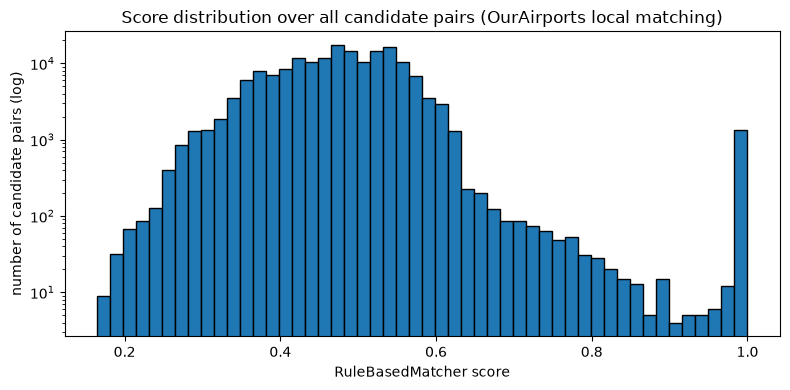

score
[0.0, 0.6)     166830
[0.6, 0.7)       4716
[0.7, 0.75)       225
[0.75, 0.8)       132
[0.8, 0.85)        60
[0.85, 0.9)        33
[0.9, 0.95)        14
[0.95, 1.0)      1342
Name: count, dtype: int64


In [16]:
print(correspondences["score"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correspondences["score"], bins=50, edgecolor="black")
ax.set_yscale("log")
ax.set_xlabel("RuleBasedMatcher score")
ax.set_ylabel("number of candidate pairs (log)")
ax.set_title("Score distribution over all candidate pairs (OurAirports local matching)")
plt.tight_layout()
plt.show()

bands = pd.cut(correspondences["score"], bins=[0, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0001], right=False)
print(bands.value_counts().sort_index())

## Sanity check against OurAirports' own duplicate labels

OurAirports names some duplicates explicitly (`duplicate fort lee heliport`). Pairing each labelled record with the unlabelled record that has the same `name_core` and `countryCode` gives a small gold standard of known duplicates. Pairs more than 5 km apart are left out: they are a common name matched to a different airport (e.g. `midland airport`).

This only measures **recall** on easy cases (the labelled duplicates are near-identical copies); it does not say how many of the other high-scoring pairs are real duplicates. That is what the manual review below is for.

In [17]:
labelled = df[df["is_labelled_duplicate"]]
originals = df[~df["is_labelled_duplicate"]]
gold = labelled.merge(originals, on=["name_core", "countryCode"], suffixes=("_dup", "_orig"))
gold["distance_km"] = [
    GeoDistanceComparator.haversine_km(a, b, c, d)
    for a, b, c, d in zip(gold["lat_dup"], gold["lon_dup"], gold["lat_orig"], gold["lon_orig"])
]
print(f"{labelled['id'].nunique()} labelled records, {gold['id_dup'].nunique()} with an unlabelled original")
print(f"Gold pairs more than 5 km apart (left out): {(gold['distance_km'] > 5).sum()}")
gold = gold[gold["distance_km"] <= 5]

gold_pairs = canonical_pairs(gold.rename(columns={"id_dup": "id1", "id_orig": "id2"})[["id1", "id2"]])
gold_scored = gold_pairs.merge(correspondences, on=["id1", "id2"], how="left")
print(f"\n{len(gold_pairs)} gold pairs, {gold_scored['score'].notna().sum()} of them are candidate pairs")
print(f"Gold pair distance: max {gold['distance_km'].max() * 1000:.1f} m")
print(f"Gold pair score: min {gold_scored['score'].min():.3f}, median {gold_scored['score'].median():.3f}")

131 labelled records, 120 with an unlabelled original
Gold pairs more than 5 km apart (left out): 2

119 gold pairs, 119 of them are candidate pairs
Gold pair distance: max 229.5 m
Gold pair score: min 0.891, median 1.000


## Manual review of high-scoring candidates

`SCORE_THRESHOLD = 0.85`, chosen from the score bands, the gold check (every gold pair scores ≥ 0.89) and a manual review of each band:
- **≥ 0.95** (~1 340 pairs): almost all real duplicates. Most pairs come from the large labelled clusters (48 copies of `duplicate mukho port heliport` alone give 1 128 pairs); the rest are identical names or typos (`salmon bar` / `salmom bar airport`) at the same coordinates.
- **0.85–0.95** (~50 pairs): mixed, roughly half real duplicates (`east kirkby airfield`, `ahlhorn air force base` / `ahlhorn airport`, `c 107 munhak heliport` / `munhak heliport c 107`). The others are an airport and a heliport at the same site (`sky ranch airport` / `sky ranch heliport`), different airfields side by side (`legate` / `marshall airfield`), or records with completely different names at identical coordinates, which may be renames. **Review these pairs by hand** (the table below lists the lowest-scoring matches first).
- **0.80–0.85**: mostly different facilities, but with a few real duplicates (`duplicateyeg` / `edmonton international airport`, `c 316 heliport`, `sfresh water bayou heliport`). Not counted as matches; listed separately below.
- **< 0.80**: almost only different heliports on neighbouring buildings.

`closed_vs_active` marks pairs where exactly one record is `closed`: these may be an old site and its replacement rather than a duplicate (team decision pending).

In [18]:
SCORE_THRESHOLD = 0.85
REVIEW_LOWER = 0.80

info = df.set_index("id")[["name", "type", "isoRegion", "lat", "lon"]]

def with_details(pairs):
    out = (pairs.join(info.add_suffix("1"), on="id1")
                .join(info.add_suffix("2"), on="id2"))
    out["distance_m"] = [
        round(GeoDistanceComparator.haversine_km(a, b, c, d) * 1000, 1)
        for a, b, c, d in zip(out["lat1"], out["lon1"], out["lat2"], out["lon2"])
    ]
    out["closed_vs_active"] = (out["type1"] == "closed") != (out["type2"] == "closed")
    return out.sort_values("score", ascending=False)

review_cols = ["id1", "id2", "name1", "name2", "type1", "type2", "isoRegion1", "isoRegion2",
               "distance_m", "closed_vs_active", "score"]

matches = with_details(correspondences[correspondences["score"] >= SCORE_THRESHOLD])
print(f"{len(matches)} candidate pairs with score >= {SCORE_THRESHOLD}")
print(f"  closed_vs_active: {matches['closed_vs_active'].sum()}")
print(f"  type combinations: {(matches['type1'] + ' + ' + matches['type2']).value_counts().head(5).to_dict()}")

# Lowest-scoring matches first: the pairs between 0.85 and 0.95 need manual review
uncertain = matches[matches["score"] < 0.95].sort_values("score")
print(f"\n{len(uncertain)} matches between {SCORE_THRESHOLD} and 0.95 to review by hand:")
uncertain[review_cols]

1389 candidate pairs with score >= 0.85
  closed_vs_active: 6
  type combinations: {'heliport + heliport': 1318, 'small_airport + small_airport': 30, 'closed + closed': 28, 'heliport + closed': 2, 'closed + heliport': 2}

47 matches between 0.85 and 0.95 to review by hand:


,id1,id2,name1,name2,type1,type2,isoRegion1,isoRegion2,distance_m,closed_vs_active,score
147322,oa_80950,oa_80951,acanana airport,acanana heliport,small_airport,heliport,VE-Z,VE-Z,0.0,False,0.851135
151834,oa_11952,oa_11953,legate airfield,marshall airfield,small_airport,small_airport,AU-VIC,AU-VIC,114.5,False,0.852520
151764,oa_9614,oa_9615,saud building helipad,majarrah building helipad,heliport,heliport,AE-SH,AE-SH,23.5,False,0.853232
120243,oa_35821,oa_36445,hyogo medical university sasayama health cente...,hyogo college medicine sasayama medical center...,heliport,heliport,JP-28,JP-28,29.9,False,0.854579
80904,oa_24177,oa_9556,rothera research station,aerodromo punto rothera,small_airport,small_airport,AQ-U-A,AQ-U-A,64.5,False,0.854656
151591,oa_68096,oa_8230,summer lakes seaplane base,lake hiawassee seaplane base,seaplane_base,seaplane_base,US-FL,US-FL,189.1,False,0.856086
169957,oa_46306,oa_49635,lake minnewashta seaplane base,andings landing seaplane base,seaplane_base,seaplane_base,US-MN,US-MN,39.6,False,0.859023
134647,oa_42002,oa_55305,namji emergency airfield,namji,small_airport,small_airport,KR-48,KR-48,123.6,False,0.859257
151484,oa_18691,oa_7780,ross international airport,ross international airport,small_airport,small_airport,CA-AB,US-MT,188.8,False,0.859484
140540,oa_50991,oa_50995,jotun fpso,jotun b platform,closed,closed,NO-XX,NO-XX,0.0,False,0.861083


### Borderline pairs (0.80–0.85)

Not counted as matches. Listed for manual review; move the threshold if many of them turn out to be duplicates.

In [19]:
borderline = with_details(correspondences[
    (correspondences["score"] >= REVIEW_LOWER) & (correspondences["score"] < SCORE_THRESHOLD)
])
print(f"{len(borderline)} borderline pairs")
borderline[review_cols]

60 borderline pairs


,id1,id2,name1,name2,type1,type2,isoRegion1,isoRegion2,distance_m,closed_vs_active,score
25338,oa_67657,oa_67855,cape air seaplanes boston harbor seaplane base,tailwind boston seaplane base,seaplane_base,seaplane_base,US-MA,US-MA,124.3,False,0.849053
172991,oa_72716,oa_72718,santa rosa municipal airport steiner field,santa rosa coddingtown airport,closed,closed,US-CA,US-CA,288.7,False,0.848739
122347,oa_34468,oa_34469,searea odaiba ichibangai building 2 helipad,searea odaiba ichibangai building 1 helipad,heliport,heliport,JP-13,JP-13,0.0,False,0.847209
140109,oa_49296,oa_49304,volar en globo balloon field,aerostat balloon field,balloonport,balloonport,MX-MEX,MX-MEX,182.0,False,0.843523
126485,oa_36707,oa_36708,hitachi software towers helipad,hitachi software towers b helipad,heliport,heliport,JP-13,JP-13,22.4,False,0.842951
157586,oa_35080,oa_35417,kasumigaura naval airfield,kashima airfield,closed,closed,JP-08,JP-08,299.4,False,0.842564
170500,oa_52413,oa_52415,mirpur khas air base,sindhri tharparkar airport,small_airport,small_airport,PK-SD,PK-SD,33.3,False,0.842141
113368,oa_25501,oa_59209,gavle sandviken airport,gavle sandviken airport,closed,medium_airport,SE-X,SE-U-A,128.2,True,0.841060
172826,oa_69180,oa_73930,greene county parachute center airport,bardstown landing strip,closed,closed,US-KY,US-KY,70.6,False,0.839989
73183,oa_5610,oa_73258,tolsona lake seaplane base,tolsona lake airport,seaplane_base,closed,US-AK,US-AK,199.8,True,0.839678


### Duplicate clusters

Duplicates can form groups larger than a pair (e.g. 50 copies of `duplicate mukho port heliport`). Connected components of the match graph show how many real-world entities are affected.

In [20]:
parent = {}

def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for a, b in zip(matches["id1"], matches["id2"]):
    parent[find(a)] = find(b)

clusters = pd.Series({record_id: find(record_id) for record_id in parent}).rename("cluster")
cluster_sizes = clusters.value_counts()
print(f"{len(clusters)} records in {len(cluster_sizes)} duplicate clusters")
print(f"Cluster sizes: {cluster_sizes.value_counts().sort_index().to_dict()}")

largest = clusters[clusters == cluster_sizes.index[0]].index
print(f"\nLargest cluster ({len(largest)} records):")
df.set_index("id").loc[largest, ["name", "type", "lat", "lon"]].head(5)

327 records in 131 duplicate clusters
Cluster sizes: {2: 126, 3: 1, 4: 2, 16: 1, 48: 1}

Largest cluster (48 records):


,name,type,lat,lon
oa_41660,duplicate mukho port heliport,heliport,37.540345,129.115255
oa_41659,duplicate mukho port heliport,heliport,37.540345,129.115255
oa_41664,duplicate mukho port heliport,heliport,37.540345,129.115255
oa_41658,duplicate mukho port heliport,heliport,37.540345,129.115255
oa_41663,duplicate mukho port heliport,heliport,37.540345,129.115255


## Save the matches

Saves the pairs with `score >= SCORE_THRESHOLD`, including the `closed_vs_active` flag.

**Not done yet:** deciding how to resolve the duplicates found (merge, flag, remove, ...), same as for Kaggle and Wikidata.

In [21]:
OUTPUT_DIR = Path("../../data/local_matching_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_csv = OUTPUT_DIR / "ourairportsLocalMatches.csv"
matches[review_cols].to_csv(output_csv, index=False)
print(f"Saved {len(matches)} matched pairs to {output_csv}")

Saved 1389 matched pairs to ../../data/local_matching_outputs/ourairportsLocalMatches.csv
